** Import Basic Libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Load** Dataset

In [ ]:
df = pd.read_csv("credit_risk_dataset.csv")

In [ ]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
print("df shape:",df.shape)

df shape: (32581, 12)


In [ ]:
print("df columns:",df.columns.tolist())


df columns: ['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [ ]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [ ]:
# check distribution of target columns

print("Loan Status Count:")
print(df["loan_status"].value_counts())


Loan Status Count:
loan_status
0    25473
1     7108
Name: count, dtype: int64


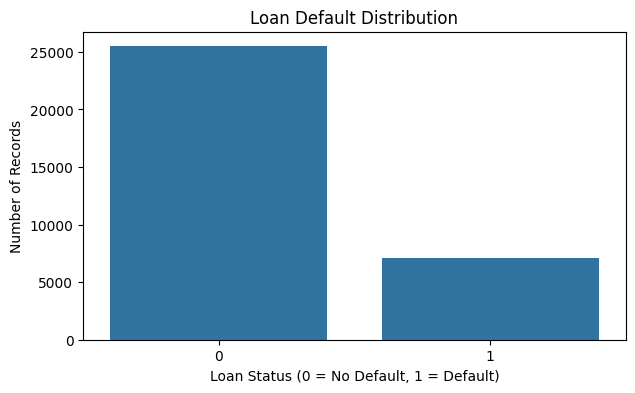

In [ ]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="loan_status")

plt.title("Loan Default Distribution")
plt.xlabel("Loan Status (0 = No Default, 1 = Default)")
plt.ylabel("Number of Records")

plt.show()

In [ ]:
# Duplicate rows count karna

print("Total Duplicate Rows:", df.duplicated().sum())


Total Duplicate Rows: 165


In [ ]:
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (32416, 12)


In [ ]:
# Features and target columns

X = df.drop(columns=["loan_status"])
y = df["loan_status"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (32416, 11)
Target Shape: (32416,)


In [ ]:
# train test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.20, random_state=42, stratify=y )

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (25932, 11)
X_test: (6484, 11)
y_train: (25932,)
y_test: (6484,)


In [ ]:
# numerical and categorical columns identify

numerical_feature = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_feature = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numerical Features:", numerical_feature)
print("Categorical Features:", categorical_feature)


Numerical Features: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Categorical Features: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numeric preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing pipeline
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_feature),
    ("cat", categorical_transformer, categorical_feature)
])

print("Preprocessing Pipeline Ready!")

Preprocessing Pipeline Ready!


In [ ]:
numeric_transformer

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

In [ ]:
categorical_transformer

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))])

In [ ]:
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['person_age', 'person_income',
                                  'person_emp_length', 'loan_amnt',
                                  'loan_int_rate', 'loan_percent_income',
                                  'cb_person_cred_hist_length']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['person_home_ownership', 'loan_intent',
                                  'loan_grade', 'cb_person_default_on_file'])])

In [ ]:
# check pipeline
X_train_processed = preprocessor.fit_transform(X_train)

print("Original Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)

Original Training Shape: (25932, 11)
Processed Training Shape: (25932, 26)


In [ ]:
# create models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model 1: Logistic Regression
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Model 2: Random Forest
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Logistic Regression Pipeline Ready!")
print("Random Forest Pipeline Ready!")


Logistic Regression Pipeline Ready!
Random Forest Pipeline Ready!


In [ ]:
logistic_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

In [ ]:
random_forest_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# 5-Fold Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

# Dono models ko dictionary mein rakhna
models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline
}

results = []

# Har model ki performance check karna
for model_name, pipeline in models.items():

    print("Evaluating:", model_name)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    results.append({
        "Model": model_name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_average_precision"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean()
    })

# Results ko DataFrame mein badalna
results_df = pd.DataFrame(results)

# ROC-AUC ke aadhar par sort karna
results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("\nModel Comparison Results:")
display(results_df.round(4))

Evaluating: Logistic Regression
Evaluating: Random Forest

Model Comparison Results:


,Model,ROC-AUC,PR-AUC,Precision,Recall,F1-Score
0,Random Forest,0.9305,0.8817,0.9730,0.7103,0.8211
1,Logistic Regression,0.8708,0.7167,0.5468,0.7792,0.6426


In [ ]:
# Hyperparameter tuning of Logistic model
from sklearn.model_selection import GridSearchCV

params = {
    "model__C": [0.1, 1, 10]
}

grid_lr = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=params,
    cv=3,
    scoring="average_precision",
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

print("Best Parameters:", grid_lr.best_params_)
print("Best PR-AUC:", grid_lr.best_score_)

Best Parameters: {'model__C': 10}
Best PR-AUC: 0.7164317123982246


In [ ]:
from sklearn.model_selection import GridSearchCV

params_rf = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20]
}

grid_rf = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=params_rf,
    cv=3,
    scoring="average_precision",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best PR-AUC:", round(grid_rf.best_score_, 4))

Best Parameters: {'model__max_depth': 20, 'model__n_estimators': 200}
Best PR-AUC: 0.8839


In [ ]:
# camparision

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Best PR-AUC": [
        grid_lr.best_score_,
        grid_rf.best_score_
    ]
})

comparison = comparison.sort_values(
    by="Best PR-AUC",
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))

,Model,Best PR-AUC
0,Random Forest,0.8839
1,Logistic Regression,0.7164


In [ ]:
if grid_rf.best_score_ > grid_lr.best_score_:
    best_model = grid_rf.best_estimator_
    best_model_name = "Random Forest"
else:
    best_model = grid_lr.best_estimator_
    best_model_name = "Logistic Regression"

print("Selected Model:", best_model_name)

Selected Model: Random Forest


In [ ]:
grid_lr.best_estimator_

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('model',
                 LogisticRegression(C=10, class_weight='balanced',
                                    max_iter=2000, random_state=42))])

In [ ]:
grid_rf.best_estimator_

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=20,
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop("loan_status", axis=1)
y = df["loan_status"]

# 1. Keep 15% for final testing
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# 2. Split remaining data into training and other validation sets
X_train, X_remaining, y_train, y_remaining = train_test_split(
    X_temp,
    y_temp,
    test_size=0.2941,
    random_state=42,
    stratify=y_temp
)

# 3. Split remaining data into calibration and threshold sets
X_cal, X_threshold, y_cal, y_threshold = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.40,
    random_state=42,
    stratify=y_remaining
)

print("Training data:", X_train.shape)
print("Calibration data:", X_cal.shape)
print("Threshold validation data:", X_threshold.shape)
print("Final test data:", X_test.shape)

Training data: (19449, 11)
Calibration data: (4862, 11)
Threshold validation data: (3242, 11)
Final test data: (4863, 11)


In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

calibrated_model = CalibratedClassifierCV(
    estimator=FrozenEstimator(best_model),
    method="sigmoid"
)

calibrated_model.fit(X_cal, y_cal)

print("Probability Calibration Complete!")

Probability Calibration Complete!


In [ ]:
calibrated_model

CalibratedClassifierCV(estimator=FrozenEstimator(estimator=Pipeline(steps=[('preprocessor',
                                                                            ColumnTransformer(transformers=[('num',
                                                                                                             Pipeline(steps=[('imputer',
                                                                                                                              SimpleImputer(strategy='median')),
                                                                                                                             ('scaler',
                                                                                                                              StandardScaler())]),
                                                                                                             ['person_age',
                                                                                                              'person_income',
                                                                                                              'person_emp_length',
                                                                                                              'loan_amnt',
                                                                                                              'loan_int_rate',
                                                                                                              'loan_percent_income',
                                                                                                              'cb_person_cred_hist_length']),
                                                                                                            ('cat',
                                                                                                             Pipeline(steps=[('imputer',
                                                                                                                              SimpleImputer(strategy='most_frequent')),
                                                                                                                             ('encoder',
                                                                                                                              OneHotEncoder(handle_unknown='ignore'))]),
                                                                                                             ['person_home_ownership',
                                                                                                              'loan_intent',
                                                                                                              'loan_grade',
                                                                                                              'cb_person_default_on_file'])])),
                                                                           ('model',
                                                                            RandomForestClassifier(class_weight='balanced',
                                                                                                   max_depth=20,
                                                                                                   n_estimators=200,
                                                                                                   n_jobs=-1,
                                                                                                   random_state=42))])))

In [ ]:
calibrated_model.classes_

array([0, 1])

In [ ]:

from sklearn.metrics import ( precision_score, recall_score,f1_score)

# Probability of default (class 1)
y_prob = calibrated_model.predict_proba(X_threshold)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds:

    # Convert probability into class prediction
    y_pred = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_threshold, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_threshold, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_threshold, y_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.10,0.9736,0.9887,0.9811
1,0.15,0.9804,0.9873,0.9838
2,0.20,0.9859,0.9873,0.9866
3,0.25,0.9943,0.9873,0.9908
4,0.30,0.9972,0.9873,0.9922
5,0.35,0.9986,0.9873,0.9929
6,0.40,1.0000,0.9859,0.9929
7,0.45,1.0000,0.9845,0.9922
8,0.50,1.0000,0.9845,0.9922
9,0.55,1.0000,0.9845,0.9922


In [ ]:
best_row = threshold_df.loc[
    threshold_df["F1-Score"].idxmax()
]

best_threshold = best_row["Threshold"]

print("Best Threshold:", best_threshold)
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1-Score:", round(best_row["F1-Score"], 4))

Best Threshold: 0.35
Precision: 0.9986
Recall: 0.9873
F1-Score: 0.9929


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    accuracy_score
)

# Predict default probabilities on unseen test data
y_test_prob = calibrated_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)

print("Selected Threshold:", best_threshold)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_test_prob), 4
))

print("PR-AUC:", round(
    average_precision_score(y_test, y_test_prob), 4
))

print("accuracy_score:", round(
    accuracy_score(y_test, y_test_pred), 2
)*100,"%")

Selected Threshold: 0.35

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      3800
           1       0.88      0.74      0.80      1063

    accuracy                           0.92      4863
   macro avg       0.91      0.86      0.88      4863
weighted avg       0.92      0.92      0.92      4863

Confusion Matrix:
[[3693  107]
 [ 276  787]]
ROC-AUC: 0.927
PR-AUC: 0.8783
accuracy_score: 92.0 %


In [ ]:
best_threshold

np.float64(0.35)

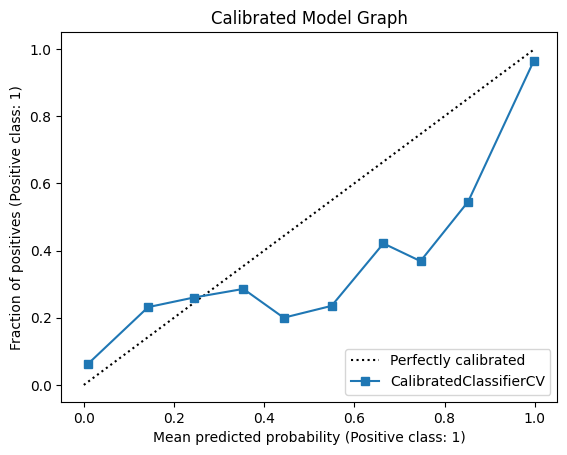

In [ ]:
# Calibrated Graph
from sklearn.calibration import CalibrationDisplay

CalibrationDisplay.from_estimator(
    calibrated_model,
    X_test,
    y_test,
    n_bins=10
)

plt.title("Calibrated Model Graph")
plt.show()

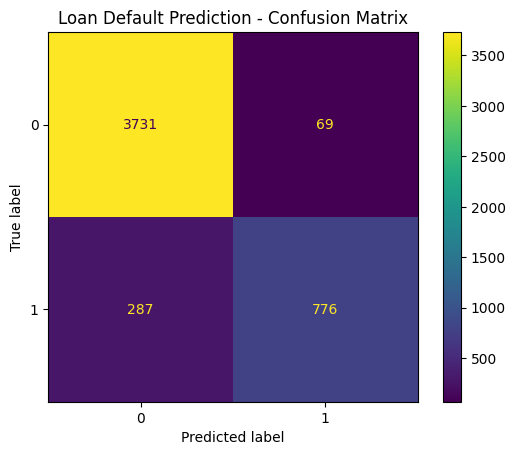

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    calibrated_model,
    X_test,
    y_test
)

plt.title("Loan Default Prediction - Confusion Matrix")
plt.show()

In [ ]:
import joblib

joblib.dump(calibrated_model, "loan_default_model.pkl")
joblib.dump(best_threshold, "best_threshold.pkl")

print("Model and Threshold Saved Successfully!")

Model and Threshold Saved Successfully!


In [ ]:
accuracy_score